# Importy

In [ ]:
from starter.load_atd import load as load_atd
import games
from kloppy import sportscode
import pandas as pd
import os, sys
import evaluation.possession_metrics as pm
from itertools import product
import matplotlib.pyplot as plt
import starter.baseline as base
import numpy as np

# Ładowanie danych

In [57]:
ball_and_player_positions = load_atd()
ball_and_player_positions_df = ball_and_player_positions.to_df()
print(ball_and_player_positions_df.head())
path = games.asset_paths()['smart_tagging']
events = sportscode.load(path).to_df()
print(events.head())

   period_id              timestamp  frame_id ball_state ball_owning_team_id  \
0          1 0 days 00:00:00.040000         1       None                None   
1          1 0 days 00:00:00.080000         2       None                None   
2          1 0 days 00:00:00.120000         3       None                None   
3          1 0 days 00:00:00.160000         4       None                None   
4          1 0 days 00:00:00.200000         5       None                None   

   ball_x  ball_y ball_z ball_speed      1_x  ...  44_d 44_s  45_x  45_y  \
0     NaN     NaN   None       None  0.33411  ...  None  NaN   NaN   NaN   
1     NaN     NaN   None       None  0.33404  ...  None  NaN   NaN   NaN   
2     NaN     NaN   None       None  0.33396  ...  None  NaN   NaN   NaN   
3     NaN     NaN   None       None  0.33389  ...  None  NaN   NaN   NaN   
4     NaN     NaN   None       None  0.33382  ...  None  NaN   NaN   NaN   

   45_d 45_s     46_x     46_y  46_d 46_s  
0  None  NaN  0.06

In [37]:
filtered_ball_and_player_positions_df = ball_and_player_positions_df[
    ((ball_and_player_positions_df["ball_x"].notna()) | (ball_and_player_positions_df["ball_x"].notna())) &
    (ball_and_player_positions_df["frame_id"] > 11185)
]

In [38]:
filtered_ball_and_player_positions_df

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
11187,1,0 days 00:07:27.520000,11188,None,None,0.50431,0.48090,None,None,NaN,...,None,NaN,0.50417,0.25273,None,0.449946,0.06057,0.39965,None,NaN
11188,1,0 days 00:07:27.560000,11189,None,None,0.51057,0.48349,None,None,NaN,...,None,NaN,0.50414,0.25286,None,0.436200,0.06057,0.39965,None,NaN
11189,1,0 days 00:07:27.600000,11190,None,None,0.51691,0.48613,None,None,NaN,...,None,NaN,0.50409,0.25293,None,0.413332,0.06057,0.39965,None,NaN
11190,1,0 days 00:07:27.640000,11191,None,None,0.52331,0.48880,None,None,NaN,...,None,NaN,0.50402,0.25295,None,0.381277,0.06057,0.39965,None,NaN
11191,1,0 days 00:07:27.680000,11192,None,None,0.52974,0.49149,None,None,NaN,...,None,NaN,0.50394,0.25291,None,0.340352,0.06057,0.39965,None,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190625,1,0 days 02:07:05.040000,190626,None,None,0.54145,1.06384,None,None,NaN,...,None,NaN,0.62662,0.51673,None,NaN,0.96168,0.51646,None,NaN
190626,1,0 days 02:07:05.080000,190627,None,None,0.54126,1.06467,None,None,NaN,...,None,NaN,0.62658,0.51655,None,NaN,0.96168,0.51646,None,NaN
190627,1,0 days 02:07:05.120000,190628,None,None,0.54110,1.06541,None,None,NaN,...,None,NaN,0.62655,0.51640,None,NaN,0.96168,0.51646,None,NaN
190628,1,0 days 02:07:05.160000,190629,None,None,0.54096,1.06605,None,None,NaN,...,None,NaN,0.62651,0.51628,None,NaN,0.96168,0.51646,None,NaN


In [39]:
negative_ball_positions_df = filtered_ball_and_player_positions_df[
    (ball_and_player_positions_df["ball_x"] < 0) |
    (ball_and_player_positions_df["ball_y"] < 0) |
    (ball_and_player_positions_df["ball_x"] > 1) |
    (ball_and_player_positions_df["ball_y"] > 1)
]

C:\Users\tomek\AppData\Local\Temp\ipykernel_43768\1946849796.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  negative_ball_positions_df = filtered_ball_and_player_positions_df[


In [42]:
negative_ball_positions_df.head(20)

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
17456,1,0 days 00:11:38.280000,17457,None,None,-0.00175,0.44313,None,None,NaN,...,None,NaN,0.16196,0.50122,None,0.117375,0.94140,0.50529,None,NaN
17457,1,0 days 00:11:38.320000,17458,None,None,-0.00421,0.44053,None,None,NaN,...,None,NaN,0.16192,0.50121,None,0.122001,0.94142,0.50528,None,NaN
17458,1,0 days 00:11:38.360000,17459,None,None,-0.00638,0.43826,None,None,NaN,...,None,NaN,0.16187,0.50120,None,0.124889,0.94143,0.50527,None,NaN
17459,1,0 days 00:11:38.400000,17460,None,None,-0.00826,0.43631,None,None,NaN,...,None,NaN,0.16183,0.50120,None,0.126151,0.94145,0.50526,None,NaN
18025,1,0 days 00:12:01.040000,18026,None,None,-0.00188,0.36793,None,None,NaN,...,None,NaN,0.07325,0.50821,None,2.903792,0.94974,0.49957,None,NaN
18026,1,0 days 00:12:01.080000,18027,None,None,-0.00755,0.35910,None,None,NaN,...,None,NaN,0.07340,0.50981,None,2.866357,0.94976,0.49956,None,NaN
18027,1,0 days 00:12:01.120000,18028,None,None,-0.01300,0.35054,None,None,NaN,...,None,NaN,0.07362,0.51140,None,2.832346,0.94977,0.49955,None,NaN
18028,1,0 days 00:12:01.160000,18029,None,None,-0.01823,0.34230,None,None,NaN,...,None,NaN,0.07389,0.51297,None,2.802331,0.94978,0.49954,None,NaN
18029,1,0 days 00:12:01.200000,18030,None,None,-0.02319,0.33441,None,None,NaN,...,None,NaN,0.07423,0.51451,None,2.776904,0.94980,0.49953,None,NaN
18030,1,0 days 00:12:01.240000,18031,None,None,-0.02789,0.32688,None,None,NaN,...,None,NaN,0.07463,0.51604,None,2.756634,0.94981,0.49952,None,NaN


In [ ]:
cols = ['ball_x', 'ball_y']
tolerance = 0.0001

groups = []
current_group = []

reference = None
current_period = None

for row in ball_and_player_positions_df[['period_id', 'frame_id', 'timestamp'] + cols].itertuples(index=False):

    period_id, frame_id, timestamp, x, y = row
    position = np.array([x, y], dtype=float)

    # Zmiana połowy meczu
    if current_period is not None and period_id != current_period:
        if current_group:
            groups.append(current_group)

        current_group = []
        reference = None

    current_period = period_id

    # Klatka z całkowitym brakiem danych
    if np.isnan(position).all():
        if reference is not None:
            current_group.append((frame_id, timestamp, x, y))
        continue

    # Pierwsza pozycja w ciągu
    if reference is None:
        reference = position.copy()
        current_group = [(frame_id, timestamp, x, y)]
        continue

    # Porównanie z pierwszą pozycją
    # NaN w pojedynczej współrzędnej nie przerywa ciągu
    comparable = ~np.isnan(position) & ~np.isnan(reference)

    is_close = (
        np.any(comparable) and
        np.all(np.abs(position[comparable] - reference[comparable]) <= tolerance)
    )

    if is_close:
        current_group.append((frame_id, timestamp, x, y))
    else:
        groups.append(current_group)

        reference = position.copy()
        current_group = [(frame_id, timestamp, x, y)]

# Ostatni ciąg
if current_group:
    groups.append(current_group)


results = []

for group in groups:

    # Pomijamy krótsze niż 2 sekundy
    if len(group) < 50:
        continue

    results.append({
        'start_frame': group[0][0],
        'end_frame': group[-1][0],
        'start_time': group[0][1],
        'end_time': group[-1][1],
        'length': group[-1][0] - group[0][0] + 1,
        'ball_x': group[0][2],
        'ball_y': group[0][3]
    })

result_df = pd.DataFrame(results)


In [54]:
print(result_df.head(20))

    start_frame  end_frame             start_time               end_time  \
0          4198       5051 0 days 00:02:47.920000 0 days 00:03:22.040000   
1          5103      10643 0 days 00:03:24.120000 0 days 00:07:05.720000   
2         10715      11003 0 days 00:07:08.600000 0 days 00:07:20.120000   
3         11035      11187 0 days 00:07:21.400000 0 days 00:07:27.480000   
4         12831      12979 0 days 00:08:33.240000 0 days 00:08:39.160000   
5         16646      16778 0 days 00:11:05.840000 0 days 00:11:11.120000   
6         17047      17279 0 days 00:11:21.880000 0 days 00:11:31.160000   
7         17460      17826 0 days 00:11:38.400000 0 days 00:11:53.040000   
8         19029      19772 0 days 00:12:41.160000 0 days 00:13:10.880000   
9         19983      20118 0 days 00:13:19.320000 0 days 00:13:24.720000   
10        23657      23809 0 days 00:15:46.280000 0 days 00:15:52.360000   
11        23831      24097 0 days 00:15:53.240000 0 days 00:16:03.880000   
12        26

In [58]:
print(events.head(20))

   code_id  period_id              timestamp          end_timestamp  \
0        1          1 0 days 00:07:23.880000 0 days 00:07:28.880000   
1        2          1 0 days 00:33:05.240000 0 days 00:33:10.240000   
2        3          1 0 days 00:41:20.480000 0 days 00:41:25.480000   
3        4          1 0 days 00:50:18.280000 0 days 00:50:23.280000   
4        5          1 0 days 01:15:46.400000 0 days 01:15:51.400000   
5        6          1        0 days 01:48:40        0 days 01:48:45   
6        7          1 0 days 01:17:41.720000 0 days 01:18:09.400000   
7        8          1 0 days 01:18:42.760000 0 days 01:19:07.040000   
8        9          1 0 days 01:21:23.200000 0 days 01:21:44.600000   
9       10          1 0 days 01:22:46.080000 0 days 01:23:11.160000   
10      11          1 0 days 01:26:01.280000        0 days 01:27:18   
11      12          1 0 days 01:28:04.280000 0 days 01:28:22.040000   
12      13          1 0 days 01:28:53.720000 0 days 01:29:27.360000   
13    

In [63]:
set_pieces = events[events["code"] == 'SET PIECES']

In [64]:
set_pieces

,code_id,period_id,timestamp,end_timestamp,code,Team,Type,Half,Max Players in the box,Side,Direction of ball entry
0,1,1,0 days 00:07:23.880000,0 days 00:07:28.880000,SET PIECES,N/A,Kick Off (Start),1st Half,None,None,None
1,2,1,0 days 00:33:05.240000,0 days 00:33:10.240000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
2,3,1,0 days 00:41:20.480000,0 days 00:41:25.480000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
3,4,1,0 days 00:50:18.280000,0 days 00:50:23.280000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
4,5,1,0 days 01:15:46.400000,0 days 01:15:51.400000,SET PIECES,N/A,Kick Off (Start),2nd Half,None,None,None
5,6,1,0 days 01:48:40,0 days 01:48:45,SET PIECES,N/A,Kick Off (After Goal),2nd Half,None,None,None
413,414,1,0 days 01:26:52.840000,0 days 01:27:27.840000,SET PIECES,Barcelona,Corner Kick,2nd Half,None,None,None
414,415,1,0 days 00:28:24.560000,0 days 00:28:59.560000,SET PIECES,Atletic Club,Corner Kick,1st Half,None,None,None
415,416,1,0 days 00:24:37.560000,0 days 00:25:12.560000,SET PIECES,Atletic Club,Corner Kick,1st Half,None,None,None
416,417,1,0 days 01:30:57.040000,0 days 01:31:32.040000,SET PIECES,Atletic Club,Corner Kick,2nd Half,None,None,None


In [108]:
def assign_events_to_frames(ball_and_player_positions_df, events):
    frames = ball_and_player_positions_df[["frame_id", "timestamp"]].copy()

    frames["code_ids"] = [[] for _ in range(len(frames))]

    for _, event in events.iterrows():
        mask = (
            (frames["timestamp"] >= event["timestamp"]) &
            (frames["timestamp"] <= event["end_timestamp"])
        )

        frames.loc[mask, "code_ids"] = frames.loc[mask, "code_ids"].apply(
            lambda x: x + [event["code_id"]]
        )

    return frames

In [197]:
df = assign_events_to_frames(ball_and_player_positions_df, set_pieces)

In [110]:
set_pieces_with_codes = df[df["code_ids"].apply(lambda x: x != [])]
set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - 250

C:\Users\tomek\AppData\Local\Temp\ipykernel_43768\3146440351.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - 250


In [111]:
print(set_pieces_with_codes)

        frame_id              timestamp code_ids
11096      10847 0 days 00:07:23.880000      [1]
11097      10848 0 days 00:07:23.920000      [1]
11098      10849 0 days 00:07:23.960000      [1]
11099      10850        0 days 00:07:24      [1]
11100      10851 0 days 00:07:24.040000      [1]
...          ...                    ...      ...
189302    189053 0 days 02:06:12.120000    [449]
189303    189054 0 days 02:06:12.160000    [449]
189304    189055 0 days 02:06:12.200000    [449]
189305    189056 0 days 02:06:12.240000    [449]
189306    189057 0 days 02:06:12.280000    [449]

[44037 rows x 3 columns]


# Faktyczny model

In [161]:
answer = pd.DataFrame({
    "frame": range(199319),
    "label": ["X"] * 199319
})

In [162]:
print(pd.Series(events["Team"]).value_counts().to_string())

Team
Barcelona       314
Atletic Club    288
N/A              36


In [163]:
frames_with_events = assign_events_to_frames(
    ball_and_player_positions_df,
    events
)

In [164]:
print(frames_with_events)
frames_with_events.to_csv("frames.csv", index=False)

        frame_id              timestamp code_ids
0              1 0 days 00:00:00.040000       []
1              2 0 days 00:00:00.080000       []
2              3 0 days 00:00:00.120000       []
3              4 0 days 00:00:00.160000       []
4              5 0 days 00:00:00.200000       []
...          ...                    ...      ...
199314    199315 0 days 02:12:52.600000       []
199315    199316 0 days 02:12:52.640000       []
199316    199317 0 days 02:12:52.680000       []
199317    199318 0 days 02:12:52.720000       []
199318    199319 0 days 02:12:52.760000       []

[199319 rows x 3 columns]


In [165]:
combinations = events[["code", "Type"]].drop_duplicates().reset_index(drop=True)
print(combinations)

                            code                   Type
0                     SET PIECES       Kick Off (Start)
1                     SET PIECES  Kick Off (After Goal)
2             PLAYERS IN THE BOX                   None
3            BALL IN FINAL THIRD                   None
4                BALL IN THE BOX                   None
5                          GOALS                   None
6                    PROGRESSION                   None
7           ATTACKING TRANSITION                   None
8                       BUILD UP                   None
9                      LONG BALL                   None
10                    SET PIECES            Corner Kick
11                    SET PIECES               Throw-in
12                    SET PIECES              Goal Kick
13                    SET PIECES              Free Kick
14              CREATING CHANCES                   None
15     DEFENDING IN MIDDLE THIRD                   None
16          DEFENSIVE TRANSITION                

In [166]:
defending_type = ['DEFENDING IN MIDDLE THIRD', 'DEFENSIVE TRANSITION', 'DEFENDING IN ATTACKING THIRD', 'DEFENDING IN DEFENSIVE THIRD']
indeterminate_type = ['PLAYERS IN THE BOX', 'BALL IN FINAL THIRD', 'BALL IN THE BOX']
attacking_type = ['BUILD UP', 'CREATING CHANCES', 'PROGRESSION', 'ATTACKING TRANSITION', 'LONG BALL', 'GOALS']
set_piece_type = ['SET PIECES']

In [83]:
def adding(x, y, list1, list2, list3, list4, type1, type2, type3):
    if x in list1:
        if y == 'Atletic Club':
            type1 -= 1
        if y == 'Barcelona':
            type2 -= 1
    if x in list2:
        if y == 'Atletic Club':
            type1 += 1
        if y == 'Barcelona':
            type2 += 1
    if x in list3:
        if y == 'Atletic Club':
            type1 += 0
        if y == 'Barcelona':
            type2 += 0
        type3 += 0
    if x in list4:
        if y == 'Atletic Club':
            type1 += 0
        if y == 'Barcelona':
            type2 += 0
    return type1, type2, type3

In [167]:
def adding2(x, y, list1, list2, type1, type2):
    if x in list1:
        if y == 'Atletic Club':
            type2 += 1
        if y == 'Barcelona':
            type1 += 1
    if x in list2:
        if y == 'Atletic Club':
            type1 += 1
        if y == 'Barcelona':
            type2 += 1
    return type1, type2

In [85]:
def submitter(name):
    if name == 'Atletic Club':
        return 'A'
    if name == 'Barcelona':
        return 'H'
    if name == 'Dead':
        return 'D'
    return 'error'

In [168]:
codes = base.build()
basic = base.smooth(codes, 50)
basic_basic = base.smooth(codes, 0)

teams: H = Barcelona, A = Atletic Club
reading BAR-ATH_tactical_atd.txt ...
  ball located on 113488 of 199319 frames (56.9%)



In [224]:
atl_list = []
bar_list = []
dead_list = []

for i in range(len(frames_with_events)):
    atl = 0
    bar = 0
    dead = 0
    if (negative_ball_positions_df["frame_id"] == i).any():
        dead += 5
    if (set_pieces_with_codes["frame_id"] == i).any():
        dead += 3
    if ((result_df["start_frame"] <= i) & (result_df["end_frame"] >= i)).any():
        dead += 1
    if basic[i] == 'H' or basic[i] == 'A':
        if basic[i] == 'H':
            bar += 2
        else:
            atl += 2
    if basic_basic[i] == 'H' or basic_basic[i] == 'A':
            if basic_basic[i] == 'H':
                bar += 1
            else:
                atl += 1
    if not frames_with_events.loc[i, "code_ids"]:
        dead += 1
    else:
        ids = frames_with_events.loc[i, "code_ids"]

        for id in ids:
                
            event = events.loc[events["code_id"] == id].iloc[0]
            atl_local, bar_local = adding2(event["code"], event["Team"], defending_type, attacking_type, 0, 0)

            atl += atl_local
            bar += bar_local
    values = {
                "A": atl,
                "H": bar,
                "D": dead
            }

    maximum = max(values.values())

    winners = [name for name, value in values.items() if value == maximum]
                
    if len(winners) == 1:
        answer.loc[i, "label"] = winners[0]
    else:
        # co do zasady lepiej działa danie na barcelone (wyższa kultura gry)
        answer.loc[i, "label"] = winners[0]
    atl_list.append(atl)
    bar_list.append(bar)
    dead_list.append(dead)

            


In [193]:
print(answer)
print(pd.Series(answer["label"]).value_counts().to_string())

         frame label
0            0     D
1            1     D
2            2     D
3            3     D
4            4     D
...        ...   ...
199314  199314     D
199315  199315     D
199316  199316     D
199317  199317     D
199318  199318     D

[199319 rows x 2 columns]
label
D    81932
H    68841
A    48546


In [185]:
from matplotlib.ticker import MultipleLocator

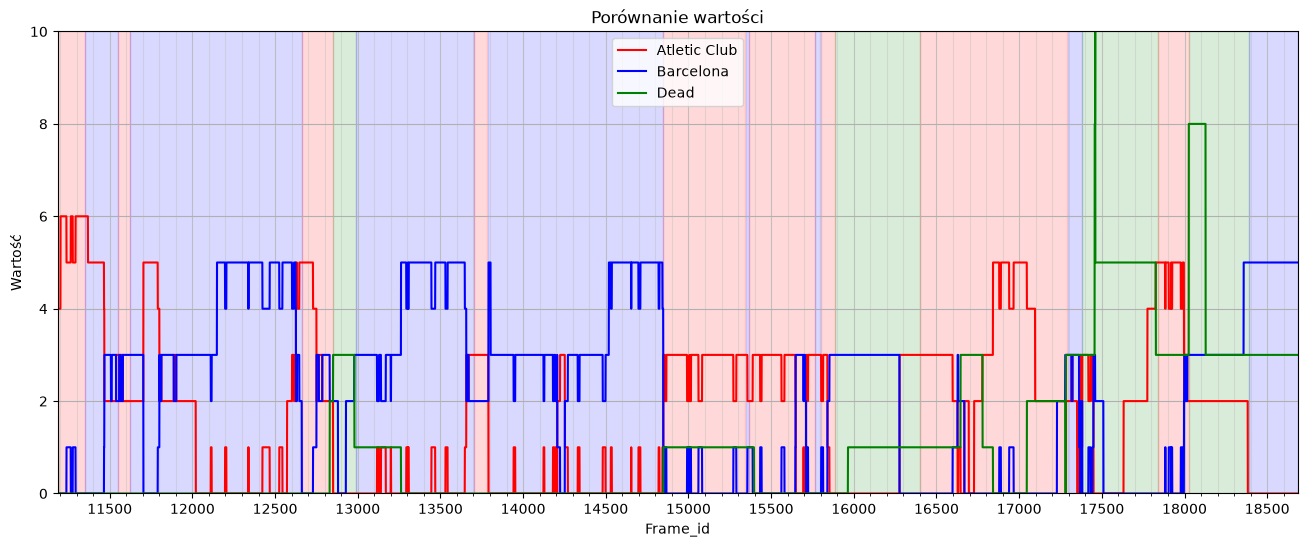

In [ ]:
plt.figure(figsize=(16, 6))

plt.plot(atl_list, color='red', label='Atletic Club')
plt.plot(bar_list, color='blue', label='Barcelona')
plt.plot(dead_list, color='green', label='Dead')

plt.xlabel('Frame_id')
plt.ylabel('Wartość')
plt.title('Porównanie wartości')

ax = plt.gca()

# Siatka co 100
ax.xaxis.set_minor_locator(MultipleLocator(100))

# Napisy na osi X co 500
ax.xaxis.set_major_locator(MultipleLocator(500))

# Siatka główna i pomocnicza
ax.grid(which='major', axis='x', alpha=0.7)
ax.grid(which='minor', axis='x', alpha=0.3)

plt.axvspan(11185, 11350, color='red', alpha=0.15)
plt.axvspan(11351, 11552, color='blue', alpha=0.15)
plt.axvspan(11553, 11623, color='red', alpha=0.15)
plt.axvspan(11624, 12664, color='blue', alpha=0.15)
plt.axvspan(12665, 12850, color='red', alpha=0.15)
plt.axvspan(12851, 12988, color='green', alpha=0.15)
plt.axvspan(12989, 13703, color='blue', alpha=0.15)
plt.axvspan(13704, 13784, color='red', alpha=0.15)
plt.axvspan(13785, 14845, color='blue', alpha=0.15)
plt.axvspan(14846, 15345, color='red', alpha=0.15)
plt.axvspan(15346, 15364, color='blue', alpha=0.15)
plt.axvspan(15365, 15765, color='red', alpha=0.15)
plt.axvspan(15766, 15798, color='blue', alpha=0.15)
plt.axvspan(15799, 15888, color='red', alpha=0.15)
plt.axvspan(15889, 16399, color='green', alpha=0.15)
plt.axvspan(16400, 17292, color='red', alpha=0.15)
plt.axvspan(17293, 17379, color='blue', alpha=0.15)
plt.axvspan(17380, 17837, color='green', alpha=0.15)
plt.axvspan(17838, 18026, color='red', alpha=0.15)
plt.axvspan(18027, 18388, color='green', alpha=0.15)
plt.axvspan(18389, 18684, color='blue', alpha=0.15)

plt.xlim(11185, 18684)
plt.ylim(0,10)

plt.legend()
plt.grid(True)
plt.show()

# Test hiperparametrów

In [ ]:
def test(parameters):
    if len(parameters) == 4:
        local_answer = pd.DataFrame({
            "frame": range(199319),
            "label": ["X"] * 199319
        })
        def adding(x, y, list1, list2, list3, list4, type1, type2, type3):
            if x in list1:
                if y == 'Atletic Club':
                    type1 -= parameters[0]
                if y == 'Barcelona':
                    type2 -= parameters[0]
            if x in list2:
                if y == 'Atletic Club':
                    type1 += parameters[1]
                if y == 'Barcelona':
                    type2 += parameters[1]
            if x in list3:
                if y == 'Atletic Club':
                    type1 += parameters[2]
                if y == 'Barcelona':
                    type2 += parameters[2]
                type3 += parameters[2]
            if x in list4:
                if y == 'Atletic Club':
                    type1 += parameters[3]
                if y == 'Barcelona':
                    type2 += parameters[3]
            return type1, type2, type3
        for i in range(len(frames_with_events)):
    
            if not frames_with_events.loc[i, "code_ids"]:
                local_answer.loc[i, "label"] = "D"
            else:
                ids = frames_with_events.loc[i, "code_ids"]
                
                atl = 0
                bar = 0
                dead = 0

                for id in ids:
                    
                    event = events.loc[events["code_id"] == id].iloc[0]
                    atl, bar, dead = adding(event["code"], event["Team"], defending_type, attacking_type, set_piece_type, indeterminate_type, atl, bar, dead)

                values = {
                    "Atletic Club": atl,
                    "Barcelona": bar,
                    "Dead": dead
                }

                maximum = max(values.values())

                winners = [name for name, value in values.items() if value == maximum]

                if len(winners) == 1:
                    local_answer.loc[i, "label"] = submitter(winners[0])
                else:
                    # co do zasady lepiej działa danie na barcelone (wyższa kultura gry)
                    local_answer.loc[i, "label"] = submitter(winners[1])
                    
        local_answer.to_csv("evaluation/results/local_answer.csv", index=False)

        sys.path.insert(0, os.path.abspath('../evaluation'))

        gt = pm.label_codes(pm.read_label_csv('evaluation/gt/BAR-ATH_possession_gt_public.csv'))
        def score(labels):
            """The two headline numbers, plus how many possessions the labels imply."""
            r = pm.evaluate(gt, pm.label_codes(labels))
            return {'macroF1': round(r['macro_f1'], 4), 'spellF1': round(r['spell_f1_mean'], 4),
                    'possessions': r['n_pred_spells'],
                    'mean_dur_s': round(r['mean_spell_duration_s'], 1)}

        print(f'parameters: {parameters}')
        print(score(local_answer))

    else:
        return "error"

In [15]:
values = [0, 0.5, 1, 2]

possible_parameters = [list(x) for x in product(values, repeat=4)]
for parameters in possible_parameters:
    test(parameters)

parameters: [0, 0, 0, 0]
{'macroF1': 0.3468, 'spellF1': 0.1524, 'possessions': 4, 'mean_dur_s': 56.6}
parameters: [0, 0, 0, 0.5]
{'macroF1': 0.4383, 'spellF1': 0.15, 'possessions': 7, 'mean_dur_s': 32.4}
parameters: [0, 0, 0, 1]
{'macroF1': 0.4383, 'spellF1': 0.15, 'possessions': 7, 'mean_dur_s': 32.4}
parameters: [0, 0, 0, 2]
{'macroF1': 0.4383, 'spellF1': 0.15, 'possessions': 7, 'mean_dur_s': 32.4}
parameters: [0, 0, 0.5, 0]
{'macroF1': 0.4251, 'spellF1': 0.1524, 'possessions': 4, 'mean_dur_s': 44.7}
parameters: [0, 0, 0.5, 0.5]
{'macroF1': 0.4222, 'spellF1': 0.0696, 'possessions': 6, 'mean_dur_s': 34.9}
parameters: [0, 0, 0.5, 1]
{'macroF1': 0.4254, 'spellF1': 0.0696, 'possessions': 6, 'mean_dur_s': 35.0}
parameters: [0, 0, 0.5, 2]
{'macroF1': 0.4254, 'spellF1': 0.0696, 'possessions': 6, 'mean_dur_s': 35.0}
parameters: [0, 0, 1, 0]
{'macroF1': 0.4251, 'spellF1': 0.1524, 'possessions': 4, 'mean_dur_s': 44.7}
parameters: [0, 0, 1, 0.5]
{'macroF1': 0.4205, 'spellF1': 0.0696, 'possessio

In [ ]:
def test2(parameter):
    set_pieces_with_codes = df[df["code_ids"].apply(lambda x: x != [])]
    set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - parameter
    answer_local = pd.DataFrame({
        "frame": range(199319),
        "label": ["X"] * 199319
    })
    was_dead = 1
    atl_list = []
    bar_list = []
    ranges = list(zip(result_df['start_frame'], result_df['end_frame']))
    for i in range(len(frames_with_events)):
        if ((negative_ball_positions_df["frame_id"] == i).any() or (set_pieces_with_codes["frame_id"] == i).any()):
            answer_local.loc[i, "label"] = "D"
            was_dead = 1


        else:
            if was_dead == 1:
                was_dead = 0

            # kradniemy z ich rozwiązania
            if not frames_with_events.loc[i, "code_ids"]:
                answer_local.loc[i, "label"] = basic[i]

            else:
                ids = frames_with_events.loc[i, "code_ids"]
                
                atl = 0
                bar = 0

                for id in ids:
                    
                    event = events.loc[events["code_id"] == id].iloc[0]
                    atl, bar = adding2(event["code"], event["Team"], defending_type, attacking_type, atl, bar)

                values = {
                    "Atletic Club": atl,
                    "Barcelona": bar
                }
                atl_list.append(atl)
                bar_list.append(bar)

                maximum = max(values.values())

                if maximum == 0:
                    answer_local.loc[i, "label"] = basic[i]
                else:
                    winners = [name for name, value in values.items() if value == maximum]

                    if len(winners) == 1:
                        answer_local.loc[i, "label"] = submitter(winners[0])
                    else:
                        # co do zasady lepiej działa danie na barcelone (wyższa kultura gry)
                        answer_local.loc[i, "label"] = submitter(winners[1])
    answer_local.to_csv("evaluation/results/answer_local.csv", index=False)
    
    sys.path.insert(0, os.path.abspath('../evaluation'))
    
    gt = pm.label_codes(pm.read_label_csv('evaluation/gt/BAR-ATH_possession_gt_public.csv'))
    def score(labels):
        """The two headline numbers, plus how many possessions the labels imply."""
        r = pm.evaluate(gt, pm.label_codes(labels))
        return {'macroF1': round(r['macro_f1'], 4), 'spellF1': round(r['spell_f1_mean'], 4),
            'possessions': r['n_pred_spells'],
            'mean_dur_s': round(r['mean_spell_duration_s'], 1)}
    
    print(f'parameters: {parameters}')
    print(score(answer_local))

In [107]:
possible_parameters = [0, 50, 100, 250, 500, 750, 1000]
for parameters in possible_parameters:
    test2(parameters)

C:\Users\tomek\AppData\Local\Temp\ipykernel_43768\269432560.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - parameter


parameters: 0
{'macroF1': 0.6629, 'spellF1': 0.2211, 'possessions': 21, 'mean_dur_s': 11.8}


C:\Users\tomek\AppData\Local\Temp\ipykernel_43768\269432560.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - parameter


parameters: 50
{'macroF1': 0.674, 'spellF1': 0.2211, 'possessions': 21, 'mean_dur_s': 11.8}


C:\Users\tomek\AppData\Local\Temp\ipykernel_43768\269432560.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - parameter


parameters: 100
{'macroF1': 0.6837, 'spellF1': 0.2333, 'possessions': 19, 'mean_dur_s': 13.0}


... (4 outputs left out)

C:\Users\tomek\AppData\Local\Temp\ipykernel_43768\269432560.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - parameter


parameters: 750
{'macroF1': 0.6475, 'spellF1': 0.2788, 'possessions': 16, 'mean_dur_s': 14.4}


C:\Users\tomek\AppData\Local\Temp\ipykernel_43768\269432560.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - parameter


parameters: 1000
{'macroF1': 0.5743, 'spellF1': 0.2581, 'possessions': 14, 'mean_dur_s': 16.1}


In [208]:
def test3(parameters):
    lanswer = pd.DataFrame({
            "frame": range(199319),
            "label": ["X"] * 199319
        })
    set_pieces_with_codes = df[df["code_ids"].apply(lambda x: x != [])]
    set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - parameters[0]
    for i in range(len(frames_with_events)):
        atl = 0
        bar = 0
        dead = 0
        if (negative_ball_positions_df["frame_id"] == i).any():
            dead += 5
        if (set_pieces_with_codes["frame_id"] == i).any():
            dead += 3
        if ((result_df["start_frame"] <= i) & (result_df["end_frame"] >= i)).any():
            dead += 1
        if basic[i] == 'H' or basic[i] == 'A':
            if basic[i] == 'H':
                bar += 2
            else:
                atl += 2
        if basic_basic[i] == 'H' or basic_basic[i] == 'A':
                if basic_basic[i] == 'H':
                    bar += 1
                else:
                    atl += 1
        if not frames_with_events.loc[i, "code_ids"]:
            dead += 1
        else:
            ids = frames_with_events.loc[i, "code_ids"]

            for id in ids:
                    
                event_type = frames_with_events
                if i > 1000:
                    event_type["frame_id"] = event_type["frame_id"] - parameters[1]
                    event = event_type.loc[events["code_id"] == id].iloc[0]
                    atl_local, bar_local = adding2(event["code"], event["Team"], defending_type, attacking_type, 0, 0)

                    atl += atl_local
                    bar += bar_local

        values = {
                    "A": atl,
                    "H": bar,
                    "D": dead
                }

        maximum = max(values.values())

        winners = [name for name, value in values.items() if value == maximum]
                    
        if len(winners) == 1:
            lanswer.loc[i, "label"] = winners[0]
        else:
            # co do zasady lepiej działa danie na barcelone (wyższa kultura gry)
            lanswer.loc[i, "label"] = winners[0]
    lanswer.to_csv("evaluation/results/answer_local.csv", index=False)
        
    sys.path.insert(0, os.path.abspath('../evaluation'))
        
    gt = pm.label_codes(pm.read_label_csv('evaluation/gt/BAR-ATH_possession_gt_public.csv'))
    def score(labels):
        """The two headline numbers, plus how many possessions the labels imply."""
        r = pm.evaluate(gt, pm.label_codes(labels))
        return {'macroF1': round(r['macro_f1'], 4), 'spellF1': round(r['spell_f1_mean'], 4),
            'possessions': r['n_pred_spells'],
            'mean_dur_s': round(r['mean_spell_duration_s'], 1)}
        
    print(f'parameters: {parameters}')
    print(score(lanswer))

            


In [209]:
print(events)

    code_id  period_id              timestamp          end_timestamp  \
0         1          1 0 days 00:07:23.880000 0 days 00:07:28.880000   
1         2          1 0 days 00:33:05.240000 0 days 00:33:10.240000   
2         3          1 0 days 00:41:20.480000 0 days 00:41:25.480000   
3         4          1 0 days 00:50:18.280000 0 days 00:50:23.280000   
4         5          1 0 days 01:15:46.400000 0 days 01:15:51.400000   
..      ...        ...                    ...                    ...   
633     634          1 0 days 00:35:12.160000 0 days 00:35:42.160000   
634     635          1 0 days 01:44:32.960000 0 days 01:45:02.960000   
635     636          1 0 days 01:57:47.640000 0 days 01:58:17.640000   
636     637          1 0 days 01:34:47.120000 0 days 01:35:17.120000   
637     638          1 0 days 01:22:41.720000 0 days 01:23:11.720000   

                             code          Team                   Type  \
0                      SET PIECES           N/A       Kick Of

In [210]:
possible_parameters = [[0,0], [0,50], [0,100], [0,250], [50,0], [50,50], [50,100], [50,250], [100,0], [100,50], [100,100], [100,250], [250,0], [250,50], [250,100], [250,250]]
for parameters in possible_parameters:
    test3(parameters)

C:\Users\tomek\AppData\Local\Temp\ipykernel_43768\1397221767.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_pieces_with_codes["frame_id"] = set_pieces_with_codes["frame_id"] - parameters[0]


IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

# Oddanie modelu

In [219]:
def clean_short_sequences(labels_df, min_length=100):
    result = labels_df.copy()
    labels = result["label"].to_numpy(copy=True)

    if len(labels) == 0:
        return result

    # Wyznaczenie granic kolejnych ciągów etykiet
    starts = np.r_[0, np.flatnonzero(labels[1:] != labels[:-1]) + 1]
    ends = np.r_[starts[1:], len(labels)]

    # Sprawdzamy każdy ciąg poza pierwszym i ostatnim
    for j in range(1, len(starts) - 1):
        current_length = ends[j] - starts[j]
        previous_length = ends[j - 1] - starts[j - 1]

        previous_label = labels[starts[j - 1]]
        next_label = labels[starts[j + 1]]

        if (
            current_length < min_length
            and previous_length >= min_length
            and previous_label == next_label
        ):
            labels[starts[j]:ends[j]] = previous_label

    result["label"] = labels
    return result


In [220]:
answer2 = clean_short_sequences(answer, min_length=100)

In [ ]:
answer.to_csv("evaluation/results/answer.csv", index=False)

In [ ]:
!python evaluation/validate_submission.py evaluation/results/answer.csv

OK    answer2.csv
      199319 rows, frame 0..199318

      label counts
        H    69932   35.1%
        A    47048   23.6%
        D    82339   41.3%
        X        0    0.0%

      reports 609 possessions of mean 7.7 s

Valid. Note this checks the format only -- it says nothing about whether the labels are right.
Score it against the public ground truth with run_evaluation.py.


In [223]:
sys.path.insert(0, os.path.abspath('../evaluation'))

gt = pm.label_codes(pm.read_label_csv('evaluation/gt/BAR-ATH_possession_gt_public.csv'))

def score(labels):
    """The two headline numbers, plus how many possessions the labels imply."""
    r = pm.evaluate(gt, pm.label_codes(labels))
    return {'macroF1': round(r['macro_f1'], 4), 'spellF1': round(r['spell_f1_mean'], 4),
            'possessions': r['n_pred_spells'],
            'mean_dur_s': round(r['mean_spell_duration_s'], 1)}

print('ground truth: 17 possessions of mean 14.2 s')
print(score(answer))

ground truth: 17 possessions of mean 14.2 s
{'macroF1': 0.7238, 'spellF1': 0.2313, 'possessions': 47, 'mean_dur_s': 5.7}


Wynik z "X":

ground truth: 17 possessions of mean 14.2 s

{'macroF1': 0.3635, 'spellF1': 0.176, 'possessions': 8, 'mean_dur_s': 37.4}


Wynik z "D":

ground truth: 17 possessions of mean 14.2 s

{'macroF1': 0.472, 'spellF1': 0.2923, 'possessions': 9, 'mean_dur_s': 25.1}


Wynik z winners[1]:

ground truth: 17 possessions of mean 14.2 s

{'macroF1': 0.5336, 'spellF1': 0.3077, 'possessions': 9, 'mean_dur_s': 24.3}


Wynik z deciding_type i winners[1]:

ground truth: 17 possessions of mean 14.2 s

{'macroF1': 0.4965, 'spellF1': 0.25, 'possessions': 7, 'mean_dur_s': 31.9}

Wynik z deciding_type:

ground truth: 17 possessions of mean 14.2 s

{'macroF1': 0.4494, 'spellF1': 0.1636, 'possessions': 5, 'mean_dur_s': 45.1}

Wynik z dużym zyskiem za 'set piece':

ground truth: 17 possessions of mean 14.2 s

{'macroF1': 0.4276, 'spellF1': 0.0762, 'possessions': 4, 'mean_dur_s': 52.3}

Wynik  z dużym zyskiem za 'set piece' i pozostałymi najlepszymi parametrami:

ground truth: 17 possessions of mean 14.2 s

{'macroF1': 0.5497, 'spellF1': 0.25, 'possessions': 7, 'mean_dur_s': 25.6}

# Wnioski

Najlepsze do tej pory funkcje:

In [19]:
def adding(x, y, list1, list2, list3, list4, type1, type2, type3):
    if x in list1:
        if y == 'Atletic Club':
            type1 -= 1
        if y == 'Barcelona':
            type2 -= 1
    if x in list2:
        if y == 'Atletic Club':
            type1 += 1
        if y == 'Barcelona':
            type2 += 1
    if x in list3:
        if y == 'Atletic Club':
            type1 += 1
        if y == 'Barcelona':
            type2 += 1
        type3 += 1
    if x in list4:
        if y == 'Atletic Club':
            type1 += 0
        if y == 'Barcelona':
            type2 += 0
    return type1, type2, type3

In [ ]:
for i in range(len(frames_with_events)):
    
    if not frames_with_events.loc[i, "code_ids"]:
        answer.loc[i, "label"] = "D"
    else:
        ids = frames_with_events.loc[i, "code_ids"]
        
        atl = 0
        bar = 0
        dead = 0

        for id in ids:
            
            event = events.loc[events["code_id"] == id].iloc[0]
            atl, bar, dead = adding(event["code"], event["Team"], defending_type, attacking_type, set_piece_type, indeterminate_type, atl, bar, dead)

        values = {
            "Atletic Club": atl,
            "Barcelona": bar,
            "Dead": dead
        }

        maximum = max(values.values())

        winners = [name for name, value in values.items() if value == maximum]

        if len(winners) == 1:
            answer.loc[i, "label"] = submitter(winners[0])
        else:
            answer.loc[i, "label"] = submitter(winners[1])

# Do zrobienia

1) Wymyślić co zrobić przy remisie w winners

2) Znaleźć najlepsze parametry zysku i kary w funkcji adding <- to będzie leciało parę godzin

3) Wykorzystać jakoś tabele ball_and_player_df już w faktycznym decydowaniu o frame

4) Dołożyć zależność od liczby osób w polu karnym w deciding_type

5) Wyplotować atl, bar, dead jako wykres dla każdego frame i przyjrzeć się ich właściwościom

6) Lepiej trzeba wykrywać dead ball <- ustawić twardo, że zawsze od początku do końca set piece (oprócz kick off w tym twardo w pierwszej połowie atl w drugiej bar) jest dead ball, a czyj potem to decydujemy standardowo na podstawie pozostałych

7) Na ten moment wygląda, że deciding_type jest bezużyteczny (wszystkie najlepsze wyniki sa gdy jest równy 0), spróbować z parameters = [1,1,0,0] i podejściem z 6)

8) Stworzyć ręcznie tabelę na podstawie moich obserwacji i sprawdzić jaki ma wynik